# **Thyroid disease classification**

We classify each clinic record as **hypothyroid**, **hyperthyroid** or **no thyroid problem**

The file is UCI `thyroid0387.data`. The visits are from the Garvan Institute, Sydney, 1984 to early 1987. J. Ross Quinlan documented the file and donated it in 1986

The answer is a group, not a number. That is classification

## **0. Setup**

`pandas` = tables, `numpy` = numbers, `matplotlib` / `seaborn` = graph, `sklearn` = split, impute, scale, models, metrics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme()
pd.set_option("display.max_columns", 50)
print("libraries loaded")

libraries loaded


## **1. Load the raw file**

The file has no titles. The first line is already a patient, so we load it with `header=None` and look first

In [2]:
raw_path = r"data/thyroid-disease/thyroid0387.data"

df = pd.read_csv(raw_path, header=None)
print("rows, columns:", df.shape)
df.head()

rows, columns: (9172, 30)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
0,29,F,f,f,f,f,f,f,f,t,f,f,f,f,f,f,t,0.3,f,?,f,?,f,?,f,?,f,?,other,-[840801013]
1,29,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.6,t,1.9,t,128,f,?,f,?,f,?,other,-[840801014]
2,41,F,f,f,f,f,f,f,f,f,t,f,f,f,f,f,f,?,f,?,f,?,f,?,f,?,t,11,other,-[840801042]
3,36,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,?,f,?,f,?,f,?,f,?,t,26,other,-[840803046]
4,32,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,?,f,?,f,?,f,?,f,?,t,36,other,S[840803047]


### **Adding column titles**

The table above has **9172 rows** and **30 columns**, that is 0 to 29

Columns 0 to 28 are facts about the patient

Column 29 is the diagnosis and the record number combined together, for example `-[840801013]`



In [3]:
columns = [
    "age", "sex", "on_thyroxine", "query_on_thyroxine", "on_antithyroid_medication",
    "sick", "pregnant", "thyroid_surgery", "I131_treatment", "query_hypothyroid",
    "query_hyperthyroid", "lithium", "goitre", "tumor", "hypopituitary", "psych",
    "TSH_measured", "TSH", "T3_measured", "T3", "TT4_measured", "TT4",
    "T4U_measured", "T4U", "FTI_measured", "FTI", "TBG_measured", "TBG",
    "referral_source", "diagnosis_id",
]

df = pd.read_csv(raw_path, header=None, names=columns)
print("rows, columns:", df.shape)
df.head()

rows, columns: (9172, 30)


,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,diagnosis_id
0,29,F,f,f,f,f,f,f,f,t,f,f,f,f,f,f,t,0.3,f,?,f,?,f,?,f,?,f,?,other,-[840801013]
1,29,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.6,t,1.9,t,128,f,?,f,?,f,?,other,-[840801014]
2,41,F,f,f,f,f,f,f,f,f,t,f,f,f,f,f,f,?,f,?,f,?,f,?,f,?,t,11,other,-[840801042]
3,36,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,?,f,?,f,?,f,?,f,?,t,26,other,-[840803046]
4,32,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,?,f,?,f,?,f,?,f,?,t,36,other,S[840803047]


## **2. Split the last column**

`diagnosis_id` looks like `-[840801013]`. The letters are the diagnosis. The number is only a file label

We will not give either one to the classifier. The diagnosis is the answer. The record number is not a medical fact

In [4]:
df["diagnosis"] = df["diagnosis_id"].str.extract(r"^([^\[]+)\[")
df["record_id"] = df["diagnosis_id"].str.extract(r"\[(\d+)\]")
df = df.drop(columns=["diagnosis_id"])

print("rows, columns:", df.shape)
df[["diagnosis", "record_id"]].head()

rows, columns: (9172, 31)


,diagnosis,record_id
0,-,840801013
1,-,840801014
2,-,840801042
3,-,840803046
4,S,840803047


### **Saving the table as CSV (still not cleaned)**

In [5]:
df.to_csv(r"data/thyroid0387.csv", index=False)
print("saved data/thyroid0387.csv")

saved data/thyroid0387.csv


## **3. Look before we clean**

`?` means blank, `t` / `f` means yes / no, `query_` means the clinic suspected it

We plot first so the cleaning choices come from the file, not from a guess

### **Blank cells**



TBG is almost entirely `?`. So we will drop it later instead of filling it. The other gaps are smaller, so we fill those later, and only after the split

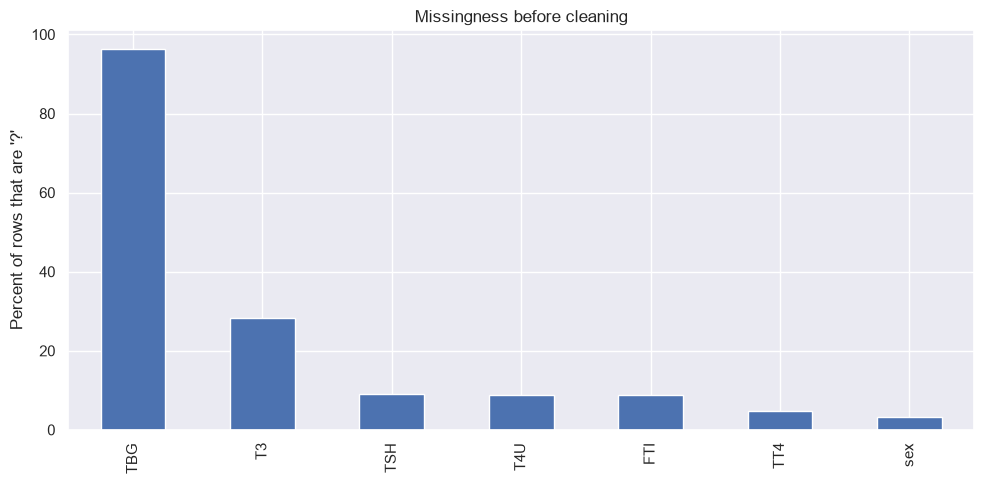

In [6]:
missing_pct = (df == "?").mean() * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing_pct.plot(kind="bar")
plt.ylabel("Percent of rows that are '?'")
plt.title("Missingness before cleaning")
plt.tight_layout()
plt.show()

### **Raw diagnosis codes and age**



The dash is no thyroid problem, and it is the most common code. The other letters are grouped later

The age plot shows a point past 60,000. That cannot be a real age

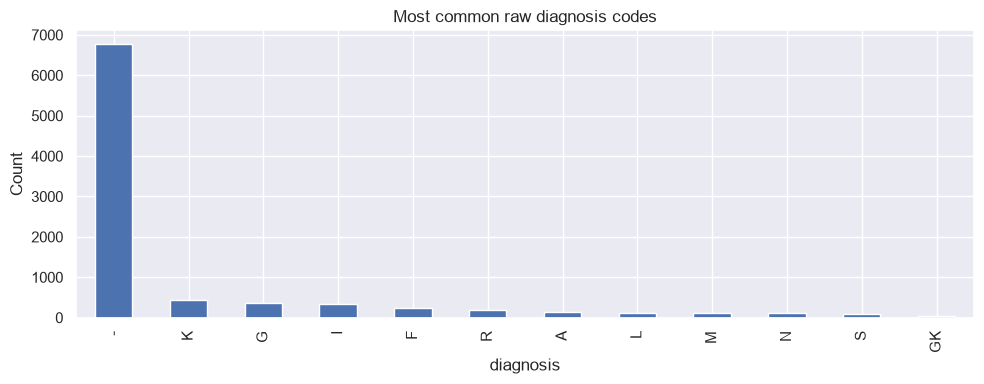

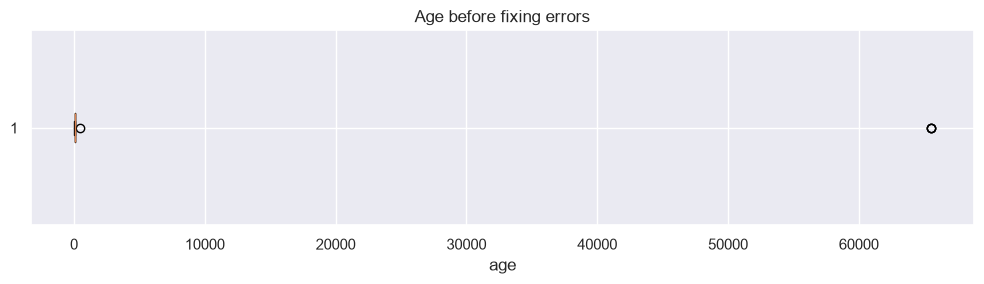

ages above 100:
        age sex diagnosis
2976    455   F         -
5710  65511   M         -
6392  65512   M         -
8105  65526   F         -


In [7]:
plt.figure(figsize=(10, 4))
df["diagnosis"].value_counts().head(12).plot(kind="bar")
plt.title("Most common raw diagnosis codes")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

age_num = pd.to_numeric(df["age"], errors="coerce")
plt.figure(figsize=(10, 3))
plt.boxplot(age_num.dropna(), orientation="horizontal")
plt.xlabel("age")
plt.title("Age before fixing errors")
plt.tight_layout()
plt.show()

print("ages above 100:")
print(df.loc[age_num > 100, ["age", "sex", "diagnosis"]].head())

## **4. Cleaning**

We fix the rows first. We do not impute or scale yet. If we did, the test rows would leak into those numbers

### **Duplicates**



`record_id` is unique, so a full-row copy that includes the id will be zero. We also check the medical columns without the id

Look-alike rows with different ids are different visits. We keep them

In [9]:
print("record_id unique?", df["record_id"].nunique() == len(df))
print("exact copies of the full row:", df.duplicated().sum())

lookalike = df.drop(columns=["record_id"]).duplicated().sum()
print("rows that copy another row's values (excluding record_id):", lookalike)

record_id unique? True
exact copies of the full row: 0
rows that copy another row's values (excluding record_id): 10


### **Turn `?` into real missing values**

Median imputation can only fill a true gap. A `?` left as text is just a word

In [10]:
df = df.replace("?", np.nan)

for col in ["age", "TSH", "T3", "TT4", "T4U", "FTI"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.isnull().sum())

age                             0
sex                           307
on_thyroxine                    0
query_on_thyroxine              0
on_antithyroid_medication       0
sick                            0
pregnant                        0
thyroid_surgery                 0
I131_treatment                  0
query_hypothyroid               0
query_hyperthyroid              0
lithium                         0
goitre                          0
tumor                           0
hypopituitary                   0
psych                           0
TSH_measured                    0
TSH                           842
T3_measured                     0
T3                           2604
TT4_measured                    0
TT4                           442
T4U_measured                    0
T4U                           809
FTI_measured                    0
FTI                           802
TBG_measured                    0
TBG                          8823
referral_source                 0
diagnosis     

### **Drop TBG**

About 96% of TBG is empty. Filling it would invent most of the column, so we drop `TBG` and `TBG_measured`

In [11]:
df = df.drop(columns=["TBG", "TBG_measured"])
print("shape after dropping TBG:", df.shape)

shape after dropping TBG: (9172, 29)


### **Impossible ages**

Four ages are above 100. We set those cells to missing and keep the rest of the row. The blood tests on that visit can still be real

Those empty ages are filled later, with the training median only

In [13]:
print("impossible ages before fix:", (df["age"] > 100).sum())
df.loc[df["age"] > 100, "age"] = np.nan
print("age missing after fix:", df["age"].isna().sum())

impossible ages before fix: 0
age missing after fix: 4


### **Build the 3 classes**

A–D = hyperthyroid, E–H = hypothyroid, `-` = no thyroid problem

Letters such as I, K, and R are other comments. We do **not** call them “no problem”. We drop those rows

In [14]:
hyper_codes = set("ABCD")
hypo_codes = set("EFGH")

def three_class(diag):
    text = str(diag)
    if text == "-":
        return "no_problem"
    letters = set(text)
    if letters & hyper_codes:
        return "hyperthyroid"
    if letters & hypo_codes:
        return "hypothyroid"
    return "other"

df["target"] = df["diagnosis"].map(three_class)
print("before dropping 'other':")
print(df["target"].value_counts())

df = df[df["target"] != "other"].copy()
print()
print("after keeping only 3 classes:")
print(df["target"].value_counts())
print("shape:", df.shape)

before dropping 'other':
target
no_problem      6771
other           1493
hypothyroid      667
hyperthyroid     241
Name: count, dtype: int64

after keeping only 3 classes:
target
no_problem      6771
hypothyroid      667
hyperthyroid     241
Name: count, dtype: int64
shape: (7679, 30)


### **Drop referral source**

`referral_source` is only the clinic name. A clinic name does not tell us if the person has a thyroid problem, so we drop it




In [15]:
# clinic name, not a disease sign
df = df.drop(columns=["referral_source"])
print("shape after dropping referral_source:", df.shape)

shape after dropping referral_source: (7679, 29)


### **Check every column that is still left**

Now we check **every remaining column** against the class

`t` is yes and `f` is no. Sex, age, and the lab numbers are in the same check, in their own tables

`diagnosis` is the answer and `record_id` is only a label, so those two are not inputs

In [16]:
# patient facts only. diagnosis is the answer, record_id is just a label
skip = ["diagnosis", "record_id", "target"]
yes_no_cols = [
    c for c in df.columns
    if c not in skip and df[c].dropna().isin(["t", "f"]).all()
]

for col in yes_no_cols:
    print(col)
    print(pd.crosstab(df[col], df["target"]))
    print()

print("sex")
print(pd.crosstab(df["sex"].fillna("missing"), df["target"]))
print()

number_cols = ["age", "TSH", "T3", "TT4", "T4U", "FTI"]
print("median by class")
print(df.groupby("target")[number_cols].median().round(2))
print()

# yes rows only, so the weak columns are easy to see
yes_rows = []
for col in yes_no_cols:
    tab = pd.crosstab(df[col], df["target"])
    if "t" in tab.index:
        yes_rows.append(tab.loc["t"].rename(col))
    else:
        yes_rows.append(pd.Series(0, index=tab.columns, name=col))

print("yes rows in each class")
print(pd.DataFrame(yes_rows).fillna(0).astype(int))

on_thyroxine
target        hyperthyroid  hypothyroid  no_problem
on_thyroxine                                       
f                      235          641        5953
t                        6           26         818

query_on_thyroxine
target              hyperthyroid  hypothyroid  no_problem
query_on_thyroxine                                       
f                            239          659        6658
t                              2            8         113

on_antithyroid_medication
target                     hyperthyroid  hypothyroid  no_problem
on_antithyroid_medication                                       
f                                   234          663        6690
t                                     7            4          81

sick
target  hyperthyroid  hypothyroid  no_problem
sick                                         
f                236          647        6509
t                  5           20         262

pregnant
target    hyperthyroid  hypothyroid  no_

### **Drop the columns the check does not support**

We drop only after the tables above

`hypopituitary` has no yes row, so it cannot separate anyone

Every `goitre` yes is no problem


In [17]:
df = df.drop(columns=["hypopituitary", "goitre"])
print("shape after leaving those columns out:", df.shape)
print(df.columns.tolist())

shape after leaving those columns out: (7679, 27)
['age', 'sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'tumor', 'psych', 'TSH_measured', 'TSH', 'T3_measured', 'T3', 'TT4_measured', 'TT4', 'T4U_measured', 'T4U', 'FTI_measured', 'FTI', 'diagnosis', 'record_id', 'target']


## **5. Look again after cleaning**

The groups are uneven. Most rows are no problem. A classifier that always says “no problem” can look good and still miss the disease

TSH, TT4, and FTI have a long tail of high values. That is why we later use the **median**, not the mean. The numbers are also on different scales, which is why we standardize them

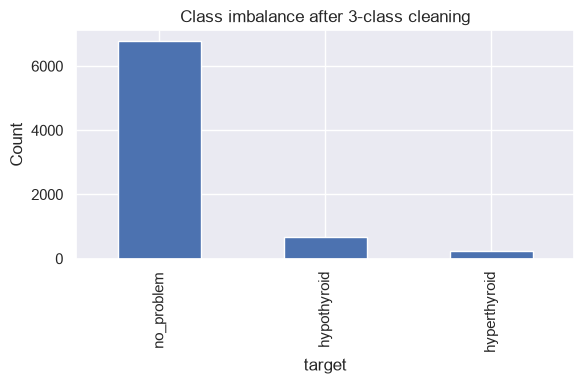

target
no_problem      6771
hypothyroid      667
hyperthyroid     241
Name: count, dtype: int64

target
no_problem      88.175544
hypothyroid      8.686027
hyperthyroid     3.138429
Name: proportion, dtype: float64


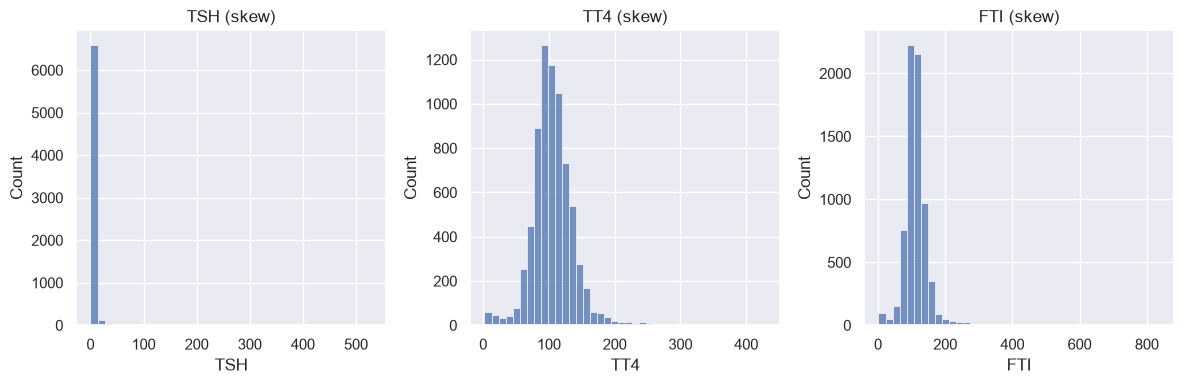

In [18]:
plt.figure(figsize=(6, 4))
df["target"].value_counts().plot(kind="bar")
plt.title("Class imbalance after 3-class cleaning")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(df["target"].value_counts())
print()
print(df["target"].value_counts(normalize=True) * 100)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["TSH", "TT4", "FTI"]):
    sns.histplot(df[col].dropna(), ax=ax, bins=40)
    ax.set_title(col + " (skew)")
plt.tight_layout()
plt.show()

## **6. Split before imputing and scaling**

We use a **stratified train-test split**. 80% learns. 20% stays locked. Stratify keeps the 3 classes in both piles. `random_state=42` makes the split repeatable

The split comes **before** the median, the one-hot columns, and the scaler. If the median used every row, the test patients would already be inside it

In [19]:
# diagnosis is the answer; record_id is only a label
X = df.drop(columns=["diagnosis", "record_id", "target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("train:", X_train.shape, "test:", X_test.shape)
print()
print("train mix (%):")
print(y_train.value_counts(normalize=True) * 100)
print()
print("test mix (%):")
print(y_test.value_counts(normalize=True) * 100)

train: (6143, 24) test: (1536, 24)

train mix (%):
target
no_problem      88.181670
hypothyroid      8.676542
hyperthyroid     3.141787
Name: proportion, dtype: float64

test mix (%):
target
no_problem      88.151042
hypothyroid      8.723958
hyperthyroid     3.125000
Name: proportion, dtype: float64


## **7. Fill, encode, and scale**

Each rule is fit on the **training** rows, then applied to the test rows.

### **Missing sex → Unknown**

Sex is not a number, so there is no median. We do not guess male or female, so we set the missing sex to unknown

In [20]:
X_train = X_train.copy()
X_test = X_test.copy()
X_train["sex"] = X_train["sex"].fillna("Unknown")
X_test["sex"] = X_test["sex"].fillna("Unknown")
X_train["sex"].value_counts()

sex
F          4007
M          1941
Unknown     195
Name: count, dtype: int64

### **Median imputation for age and the labs**

The method is median imputation. We use the middle value because a few very high tests would pull the mean up

Empty TSH still gets a number, because logistic regression and random forest cannot leave a lab cell blank. The measured flag, encoded next, tells the model when that number was not a real test

In [21]:
numeric_columns = ["age", "TSH", "T3", "TT4", "T4U", "FTI"]
imputer = SimpleImputer(strategy="median")

X_train[numeric_columns] = imputer.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = imputer.transform(X_test[numeric_columns])

print("missing labs in train after impute:")
print(X_train[numeric_columns].isnull().sum())

missing labs in train after impute:
age    0
TSH    0
T3     0
TT4    0
T4U    0
FTI    0
dtype: int64


### **Binary encoding for yes / no**

`t` becomes 1 and `f` becomes 0. This covers treatment, clinic notes, and the five measured flags

`TSH_measured = 0` means the TSH number was filled in. `TSH_measured = 1` means the clinic really did the test. The same idea applies to T3, TT4, T4U, and FTI.

In [22]:
tf_columns = [
    "on_thyroxine", "query_on_thyroxine", "on_antithyroid_medication",
    "sick", "pregnant", "thyroid_surgery", "I131_treatment",
    "query_hypothyroid", "query_hyperthyroid", "lithium", "tumor", "psych",
    "TSH_measured", "T3_measured", "TT4_measured", "T4U_measured", "FTI_measured",
]

# t = yes, f = no
for col in tf_columns:
    X_train[col] = X_train[col].map({"t": 1, "f": 0})
    X_test[col] = X_test[col].map({"t": 1, "f": 0})

X_train[tf_columns].head()

,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,tumor,psych,TSH_measured,T3_measured,TT4_measured,T4U_measured,FTI_measured
2209,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1
2696,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1
5450,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1
613,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1
4582,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1


### **One-hot encoding for sex**

One-hot encoding turns sex into numbers. We keep male and unknown. If both are 0, the person is female


In [23]:
# female is the baseline: both sex columns are 0
X_train = pd.get_dummies(X_train, columns=["sex"], drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=["sex"], drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("train columns:", len(X_train.columns))
print(X_train.columns.tolist())
print()
print(X_train[["sex_M", "sex_Unknown"]].head())

train columns: 25
['age', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'tumor', 'psych', 'TSH_measured', 'TSH', 'T3_measured', 'T3', 'TT4_measured', 'TT4', 'T4U_measured', 'T4U', 'FTI_measured', 'FTI', 'sex_M', 'sex_Unknown']

      sex_M  sex_Unknown
2209      1            0
2696      0            0
5450      0            0
613       0            0
4582      1            0


### **Standardization**

Age and the five labs are on different scales. TSH can be near 1. TT4 can be near 100. Standardization puts them on one scale so the bigger number does not win just because it is bigger

The scaler is fit on the training rows only. The 0/1 columns are left as they are.

In [24]:
scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])
X_train[numeric_columns].describe().round(3)

,age,TSH,T3,TT4,T4U,FTI
count,6143.000,6143.000,6143.000,6143.000,6143.000,6143.000
mean,0.000,-0.000,0.000,0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.716,-0.208,-2.831,-3.189,-4.905,-3.063
25%,-0.798,-0.183,-0.406,-0.534,-0.605,-0.441
50%,0.161,-0.152,-0.112,-0.071,-0.036,-0.077
75%,0.800,-0.107,0.329,0.453,0.502,0.343
max,2.399,19.769,16.647,10.023,7.300,20.401


### **Save the cleaned table (ready for machine learning)**

The fill, the encoding, and the scaling are done. This is the table the models use.

We keep the training rows and the test rows in one file, with a `split` column. SMOTE is not in this file. Those extra rows are made later, and only for training

In [25]:
train_out = X_train.copy()
train_out["target"] = y_train.values
train_out["split"] = "train"

test_out = X_test.copy()
test_out["target"] = y_test.values
test_out["split"] = "test"

ready = pd.concat([train_out, test_out], ignore_index=True)
bool_cols = ready.select_dtypes(include="bool").columns
ready[bool_cols] = ready[bool_cols].astype(int)

ready.to_csv(r"data/thyroid_dataset_ready.csv", index=False)

print("saved data/thyroid_dataset_ready.csv")
print("rows, columns:", ready.shape)
print("missing values:", ready.isnull().sum().sum())
print(ready["split"].value_counts())
print(ready["target"].value_counts())

saved data/thyroid_dataset_ready.csv
rows, columns: (7679, 27)
missing values: 0
split
train    6143
test     1536
Name: count, dtype: int64
target
no_problem      6771
hypothyroid      667
hyperthyroid     241
Name: count, dtype: int64


## **8. Balance the training rows only**

The class bar chart showed that most people have no thyroid problem. If we ignore that, the model can look good by always saying “no problem”

We compare two methods. Both stay on the training rows. The test set keeps the real clinic mix

### **SMOTE**

SMOTE makes extra training rows that look like the rare classes. They are practice copies, not new patients. We do not add them to the test set

In [26]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("before SMOTE:")
print(y_train.value_counts())
print()
print("after SMOTE (train only):")
print(y_train_smote.value_counts())

before SMOTE:
target
no_problem      5417
hypothyroid      533
hyperthyroid     193
Name: count, dtype: int64

after SMOTE (train only):
target
no_problem      5417
hyperthyroid    5417
hypothyroid     5417
Name: count, dtype: int64


### **Class weighting**

This does not make new rows. It tells the model that missing a sick person counts for more than missing a person with no thyroid problem. The weights come from the training rows only.

In [27]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
class_weights

{'hyperthyroid': np.float64(10.609671848013816),
 'hypothyroid': np.float64(3.841776110068793),
 'no_problem': np.float64(0.3780075072303243)}

## **9. Training**

We train on the training rows only. The test labels stay untouched.

The baseline always says “no problem”. It shows why accuracy can look fine while the model misses the disease

In [28]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg.fit(X_train_smote, y_train_smote)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_smote, y_train_smote)

log_reg_w = LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced")
log_reg_w.fit(X_train, y_train)

rf_w = RandomForestClassifier(random_state=42, class_weight="balanced")
rf_w.fit(X_train, y_train)

print("models are trained")

models are trained


## **10. Stratified 5-fold on the training rows**

SMOTE sits inside each fold, so the fold we score keeps the real class mix. `class_weight="balanced"` is worked out on that fold’s training rows.

We average macro F1 and macro recall, so the big no-problem class cannot hide a weak disease score. The number we report later still comes from the locked test set.

In [29]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "f1_macro": "f1_macro",
    "recall_macro": "recall_macro",
}

candidates = {
    "logreg_smote": ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "rf_smote": ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(random_state=42)),
    ]),
    "logreg_weight": LogisticRegression(
        max_iter=2000, random_state=42, class_weight="balanced"
    ),
    "rf_weight": RandomForestClassifier(
        random_state=42, class_weight="balanced"
    ),
}

rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "f1_macro_mean": scores["test_f1_macro"].mean(),
        "f1_macro_std": scores["test_f1_macro"].std(),
        "recall_macro_mean": scores["test_recall_macro"].mean(),
        "recall_macro_std": scores["test_recall_macro"].std(),
    })
    print(name)
    print("  folds macro F1   ", scores["test_f1_macro"].round(3))
    print("  folds macro recall", scores["test_recall_macro"].round(3))

cv_table = pd.DataFrame(rows).sort_values("f1_macro_mean", ascending=False)
cv_table.round(3)

logreg_smote
  folds macro F1    [0.862 0.853 0.818 0.839 0.831]
  folds macro recall [0.956 0.925 0.904 0.958 0.923]
rf_smote
  folds macro F1    [0.948 0.939 0.929 0.932 0.954]
  folds macro recall [0.97  0.941 0.933 0.966 0.96 ]
logreg_weight
  folds macro F1    [0.83  0.826 0.824 0.83  0.813]
  folds macro recall [0.959 0.948 0.937 0.962 0.938]
rf_weight
  folds macro F1    [0.945 0.943 0.935 0.916 0.959]
  folds macro recall [0.969 0.941 0.936 0.948 0.968]


,model,f1_macro_mean,f1_macro_std,recall_macro_mean,recall_macro_std
1,rf_smote,0.940,0.009,0.954,0.014
3,rf_weight,0.940,0.014,0.953,0.014
0,logreg_smote,0.841,0.016,0.933,0.021
2,logreg_weight,0.824,0.006,0.949,0.010


## **11. Evaluation**

The test rows were never used for learning. No SMOTE on the test set. We read recall and F1 first, especially for the two disease classes

Baseline
              precision    recall  f1-score   support

  no_problem       0.88      1.00      0.94      1354
 hypothyroid       0.00      0.00      0.00       134
hyperthyroid       0.00      0.00      0.00        48

    accuracy                           0.88      1536
   macro avg       0.29      0.33      0.31      1536
weighted avg       0.78      0.88      0.83      1536



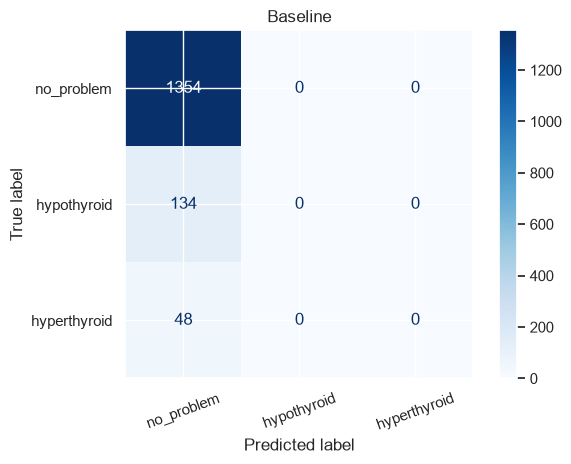

Logistic Regression + SMOTE
              precision    recall  f1-score   support

  no_problem       0.99      0.96      0.97      1354
 hypothyroid       0.88      0.94      0.91       134
hyperthyroid       0.51      0.92      0.65        48

    accuracy                           0.95      1536
   macro avg       0.79      0.94      0.85      1536
weighted avg       0.97      0.95      0.96      1536



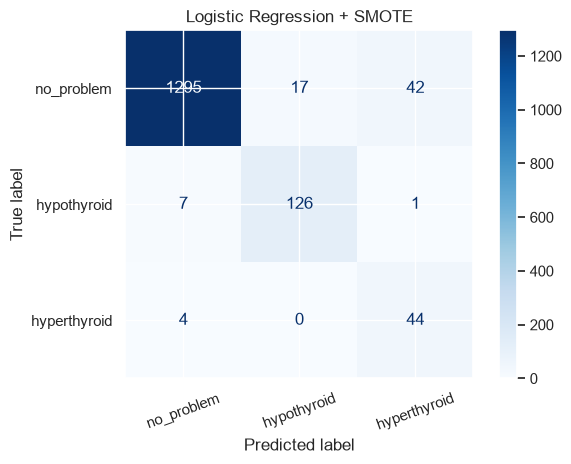

Random Forest + SMOTE
              precision    recall  f1-score   support

  no_problem       1.00      0.99      0.99      1354
 hypothyroid       0.97      0.99      0.98       134
hyperthyroid       0.77      0.92      0.84        48

    accuracy                           0.99      1536
   macro avg       0.91      0.97      0.94      1536
weighted avg       0.99      0.99      0.99      1536



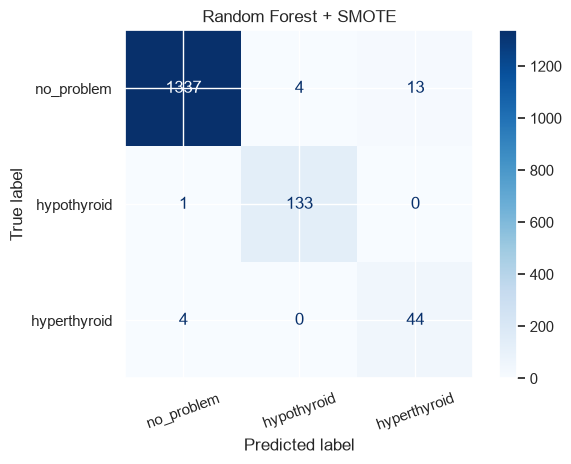

Logistic Regression + class_weight
              precision    recall  f1-score   support

  no_problem       1.00      0.94      0.97      1354
 hypothyroid       0.88      0.98      0.93       134
hyperthyroid       0.43      0.92      0.59        48

    accuracy                           0.95      1536
   macro avg       0.77      0.95      0.83      1536
weighted avg       0.97      0.95      0.95      1536



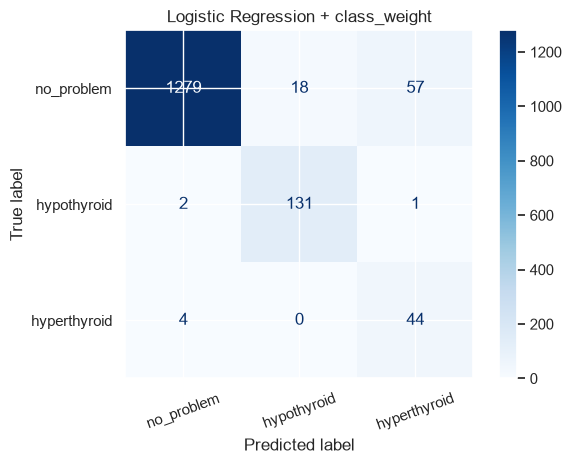

Random Forest + class_weight
              precision    recall  f1-score   support

  no_problem       0.99      0.99      0.99      1354
 hypothyroid       0.96      0.99      0.98       134
hyperthyroid       0.81      0.81      0.81        48

    accuracy                           0.98      1536
   macro avg       0.92      0.93      0.93      1536
weighted avg       0.98      0.98      0.98      1536



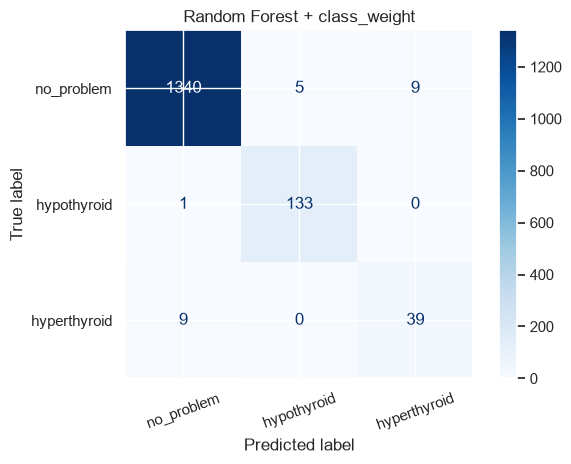

array(['no_problem', 'no_problem', 'no_problem', ..., 'no_problem',
       'no_problem', 'no_problem'], shape=(1536,), dtype=object)

In [30]:
labels = ["no_problem", "hypothyroid", "hyperthyroid"]

def test_model(name, model, Xte, yte):
    pred = model.predict(Xte)
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(yte, pred, labels=labels, zero_division=0))
    cm = confusion_matrix(yte, pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap="Blues", xticks_rotation=20)
    plt.title(name)
    plt.tight_layout()
    plt.show()
    return pred

test_model("Baseline", baseline, X_test, y_test)
test_model("Logistic Regression + SMOTE", log_reg, X_test, y_test)
test_model("Random Forest + SMOTE", rf, X_test, y_test)
test_model("Logistic Regression + class_weight", log_reg_w, X_test, y_test)
test_model("Random Forest + class_weight", rf_w, X_test, y_test)

### **One test patient**

This is one example after the full test. It is not a replacement for the test. We use random forest with SMOTE here so we can see what one row looks like.

In [32]:
sample = X_test.iloc[[12]]
actual = y_test.iloc[12]
pred = rf.predict(sample)[0]
print("actual:", actual)
print("predicted:", pred)

actual: hypothyroid
predicted: hypothyroid


### **Save the trained model**

We save the random forest that learned from the SMOTE training rows, plus the imputer and the scaler. A new row has to go through those same steps before this model can classify it.

In [ ]:
import joblib

joblib.dump(
    {"model": rf, "imputer": imputer, "scaler": scaler, "columns": X_train.columns.tolist()},
    r"data/thyroid_dataset_model.joblib",
)
print("saved data/thyroid_dataset_model.joblib")